# SmartEgg · Detección de anomalías en la telemetría

Modelo de machine learning del Proyecto 2 (bloque A). Aprende cómo se comporta la incubadora en **operación normal** con la telemetría histórica de la Fase 2 y marca las lecturas que no se parecen: picos de temperatura, calentamiento descontrolado, cambios bruscos de humedad o un sensor desconectado.

El enfoque es **no supervisado**: el histórico no trae etiquetas, así que el modelo se entrena solo con lecturas normales. Para medirlo se simulan fallas sobre días que el modelo no vio (sección 4).

Las funciones están en `smartegg_anomalias.py`; las características se calculan con `FeatureBuilder` de `anomalias/anomaly_service.py`, **el mismo código que corre en vivo** en el servicio.

In [1]:
%matplotlib inline
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import smartegg_anomalias as sa

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.precision", 2)
sa.RESULTS_DIR.mkdir(parents=True, exist_ok=True)

## 1. Extracción y exploración

Los datos vienen de la base de datos Neon de la Fase 2 (tabla `telemetry_readings`, nodo `NODE-01`). `exportar_telemetria.py` los guarda en `datos/telemetria_fase2.csv`; los actuadores y el estado del sensor se leen de la trama original (`raw_payload`).

```bash
python ml/anomalias/exportar_telemetria.py
```

In [2]:
df = sa.load_telemetry()
print(f"{len(df)} lecturas del {df.recorded_at.min():%d %b %H:%M} al {df.recorded_at.max():%d %b %H:%M} (UTC)")
print(f"Intervalo típico entre lecturas: {df.time.diff().median():.1f} s")
sessions = (df.time.diff() > 120).cumsum()
print(f"Sesiones (huecos de más de 2 min): {sessions.nunique()}")
df[["temperature_c", "humidity_pct", "door_open", "heater", "fan", "occupied_slots",
    "system_enabled", "sensor_ok"]].describe().T

7899 lecturas del 18 Sep 20:20 al 02 Oct 19:22 (UTC)
Intervalo típico entre lecturas: 2.6 s
Sesiones (huecos de más de 2 min): 19


,count,mean,std,min,25%,50%,75%,max
temperature_c,7899.0,32.74,4.59,0.4,27.9,34.8,37.0,37.9
humidity_pct,7899.0,54.01,12.03,0.0,44.0,53.0,66.0,70.0
door_open,7899.0,0.25,0.43,0.0,0.0,0.0,0.0,1.0
heater,7899.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
fan,7899.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0
occupied_slots,7899.0,0.98,1.43,0.0,0.0,0.0,1.0,4.0
system_enabled,7899.0,0.92,0.27,0.0,1.0,1.0,1.0,1.0
sensor_ok,7899.0,1.00,0.06,0.0,1.0,1.0,1.0,1.0


In [3]:
print("Valores nulos por columna:")
print(df.isna().sum()[lambda s: s > 0].to_string() or "ninguno")
print(f"\nLecturas con la misma hora: {df.recorded_at.duplicated().sum()}")
print(f"Lecturas con el sistema apagado: {(df.system_enabled == 0).sum()}")
print(f"Fallas del sensor (SENSOR:0, humedad 0 % o menos de 5 °C): {df.sensor_fault.sum()}")
print(f"Ventilador encendido: {(df.fan == 1).sum()} lecturas")
print(f"Puerta abierta: {df.door_open.mean():.0%} del tiempo; foco encendido: {df.heater.mean():.0%}")
print("\nLecturas por día:")
print(df.groupby(df.recorded_at.dt.strftime("%Y-%m-%d")).size().to_string())

Valores nulos por columna:
Series([], )

Lecturas con la misma hora: 0
Lecturas con el sistema apagado: 602
Fallas del sensor (SENSOR:0, humedad 0 % o menos de 5 °C): 49
Ventilador encendido: 0 lecturas
Puerta abierta: 25% del tiempo; foco encendido: 68%

Lecturas por día:
recorded_at
2026-09-18      39
2026-09-22    2661
2026-09-23     521
2026-09-25    3298
2026-09-26      99
2026-10-02    1281


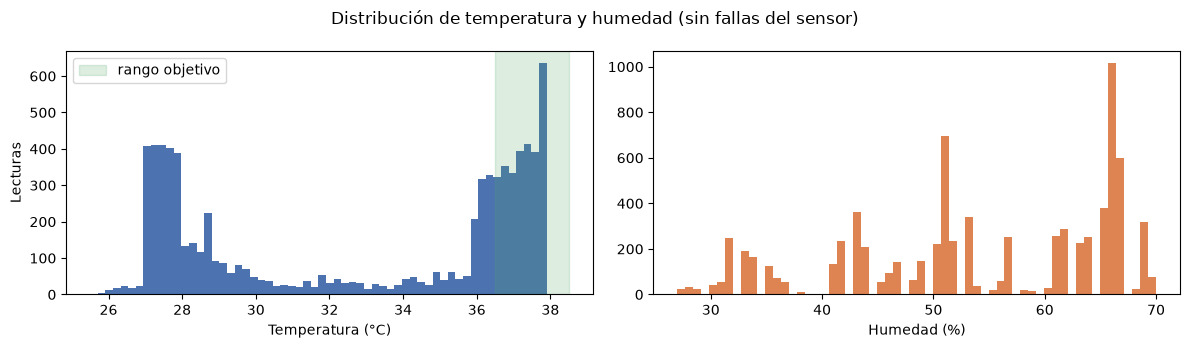

In [4]:
figure, axes = plt.subplots(1, 2, figsize=(12, 3.5))
ok = ~df.sensor_fault
axes[0].hist(df.temperature_c[ok], bins=60, color="#4c72b0")
axes[0].axvspan(36.5, 38.5, color="#55a868", alpha=0.2, label="rango objetivo")
axes[0].set_xlabel("Temperatura (°C)"); axes[0].set_ylabel("Lecturas"); axes[0].legend()
axes[1].hist(df.humidity_pct[ok], bins=60, color="#dd8452")
axes[1].set_xlabel("Humedad (%)")
figure.suptitle("Distribución de temperatura y humedad (sin fallas del sensor)")
figure.tight_layout()
figure.savefig(sa.RESULTS_DIR / "distribucion_sensores.png", dpi=150)

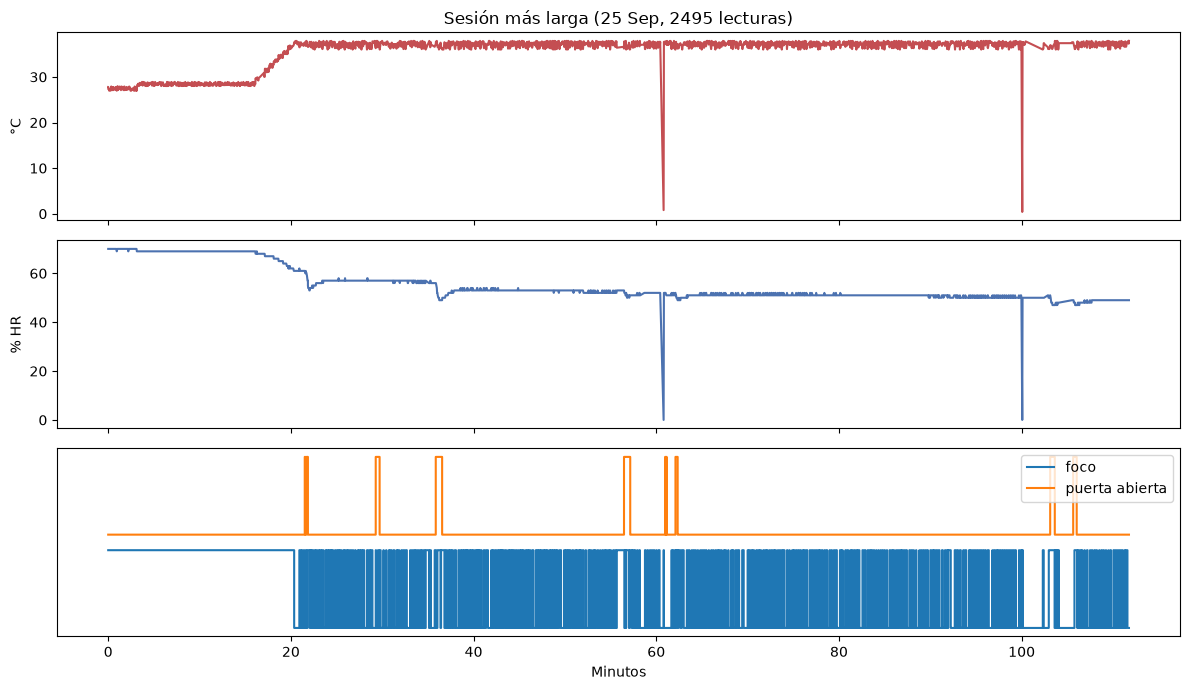

In [5]:
# Una sesión completa: calentamiento, foco y puerta
longest = sessions.value_counts().idxmax()
session = df[sessions == longest]
minutes = (session.time - session.time.iloc[0]) / 60
figure, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
axes[0].plot(minutes, session.temperature_c, color="#c44e52"); axes[0].set_ylabel("°C")
axes[1].plot(minutes, session.humidity_pct, color="#4c72b0"); axes[1].set_ylabel("% HR")
axes[2].step(minutes, session.heater, where="post", label="foco")
axes[2].step(minutes, session.door_open + 1.2, where="post", label="puerta abierta")
axes[2].set_yticks([]); axes[2].legend(loc="upper right"); axes[2].set_xlabel("Minutos")
axes[0].set_title(f"Sesión más larga ({session.recorded_at.iloc[0]:%d %b}, {len(session)} lecturas)")
figure.tight_layout()
figure.savefig(sa.RESULTS_DIR / "sesion_ejemplo.png", dpi=150)

**Lo que muestra la exploración:**

- La temperatura casi nunca llegó al rango objetivo (36.5–38.5 °C): la mayor parte del histórico es **calentamiento** desde la temperatura ambiente. Una regla fija de rangos marcaría casi todo como anómalo.
- La humedad depende del clima del día y cambia de una sesión a otra.
- El **ventilador nunca se encendió** y la puerta estuvo abierta ~25 % del tiempo (pruebas de RFID).
- Hay **fallas reales del sensor**: lecturas sueltas de menos de 5 °C con 0 % de humedad y tramas con `SENSOR:0`. No se usan para entrenar; se evalúan aparte.
- No hay nulos en temperatura ni humedad, ni lecturas repetidas.

## 2. Preprocesamiento y características

Una lectura sola no basta: 30 °C es normal durante el calentamiento y raro si la incubadora ya estaba a 37.5 °C. Por eso cada lectura se describe con **el último minuto** del mismo nodo:

| Característica | Qué mide |
| --- | --- |
| `temperatura` | temperatura actual (°C) |
| `vel_temp` | cambio de temperatura en el último minuto (°C/min) |
| `vel_hum` | cambio de humedad en el último minuto (%/min) |
| `ruido_temp` | salto medio entre lecturas seguidas (°C): sensor inestable |

Una lectura necesita al menos 20 s de historial y un hueco de más de 2 min reinicia el historial (la ESP32 se reinició). Se descartaron como características la humedad absoluta (depende del clima; su rango lo vigilan las reglas del backend), el ventilador (nunca se encendió) y el foco y la puerta: con ellos cada combinación poco común de foco y puerta salía como anomalía (~20 % de falsos positivos).

Las características se estandarizan (`StandardScaler`) dentro del pipeline. Para entrenar solo se usan lecturas con el sistema encendido y sin fallas del sensor en su ventana.

In [6]:
features = sa.build_features(df)
normal = sa.normal_mask(df, features)
print(f"{len(features)} lecturas con características; {normal.sum()} normales para entrenar")
features[normal].describe().T

7758 lecturas con características; 6802 normales para entrenar


,count,mean,std,min,25%,50%,75%,max
temperatura,6802.0,33.17,4.35,26.10,27.90,36.00,37.10,37.90
vel_temp,6802.0,0.10,0.75,-2.36,-0.37,0.00,0.48,4.38
vel_hum,6802.0,-0.22,1.45,-15.98,0.00,0.00,0.00,7.82
ruido_temp,6802.0,0.42,0.14,0.00,0.31,0.38,0.51,1.90


## 3. Algoritmo y umbral

**Local Outlier Factor** (`novelty=True`, 35 vecinos): compara la densidad de cada lectura con la de sus vecinas en el entrenamiento. Una lectura en una zona vacía del espacio de características tiene un puntaje alto.

- **Umbral:** percentil 99.9 del puntaje de las lecturas normales de entrenamiento.
- **Alerta:** 3 lecturas anómalas seguidas (~8 s). Una lectura rara suelta es ruido del sensor; una falla real se sostiene.

Se comparó con **Isolation Forest** y **One-Class SVM** (sección 5) con la misma validación, el mismo umbral y la misma alerta.

## 4. Fallas simuladas

Para medir recall se meten fallas en días que el modelo no vio (6 por cada 1000 lecturas de cada tipo):

In [7]:
pd.DataFrame({"tipo": list(sa.ANOMALY_TYPES), "descripción": list(sa.ANOMALY_TYPES.values())})

,tipo,descripción
0,pico,Pico de temperatura (+6 °C en 2 lecturas)
1,sobrecalentamiento,Calentamiento descontrolado (+0.5 °C por lectura)
2,foco_sin_calentar,Foco encendido y la temperatura baja
3,humedad,Caída brusca de humedad (−25 %)
4,sensor,Sensor desconectado (0 °C y 0 %)


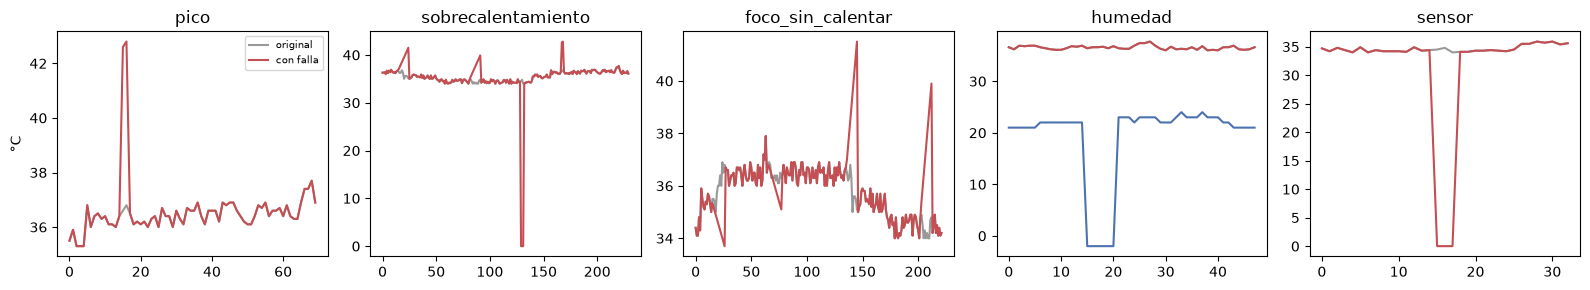

In [8]:
# Ejemplo: una falla de cada tipo sobre el día que queda fuera
fold = "25-26 sep"
injection = sa.inject_anomalies(df[df.fold == fold], seed=sa.SEED)
figure, axes = plt.subplots(1, len(sa.ANOMALY_TYPES), figsize=(16, 3))
for axis, name in zip(axes, sa.ANOMALY_TYPES):
    rows = injection.kind.index[injection.kind == name]
    start = df.index.get_loc(rows[0])
    window = df.index[max(0, start - 15):start + len(rows) + 15]
    axis.plot(range(len(window)), df.loc[window, "temperature_c"], color="#999", label="original")
    axis.plot(range(len(window)), injection.data.loc[window, "temperature_c"], color="#c44e52",
              label="con falla")
    if name == "humedad":
        axis.plot(range(len(window)), injection.data.loc[window, "humidity_pct"] - 20,
                  color="#4c72b0", label="humedad − 20")
    axis.set_title(name)
axes[0].legend(fontsize=7); axes[0].set_ylabel("°C")
figure.tight_layout()

Las lecturas del minuto siguiente a cada falla se ignoran al medir: su velocidad de cambio todavía arrastra la falla y no son ni normales ni anómalas.

## 5. Validación cruzada por día

Cada día fue una sesión distinta (otro clima, otra carga de huevos). Se entrena con 3 grupos de días, se meten fallas en el cuarto y se mide; se repite con cada grupo. Así se mide qué tan bien funciona el modelo en un día que no vio, que es lo que va a pasar en vivo.

 18-22 sep: precisión 0.747  recall 0.252  F1 0.377  falsos positivos 1.7 %  alertas falsas/h 8.2


     2 oct: precisión 0.724  recall 0.447  F1 0.553  falsos positivos 2.6 %  alertas falsas/h 17.2


    23 sep: precisión 1.000  recall 0.238  F1 0.385  falsos positivos 0.0 %  alertas falsas/h 0.0


 25-26 sep: precisión 0.973  recall 0.259  F1 0.409  falsos positivos 0.2 %  alertas falsas/h 1.1


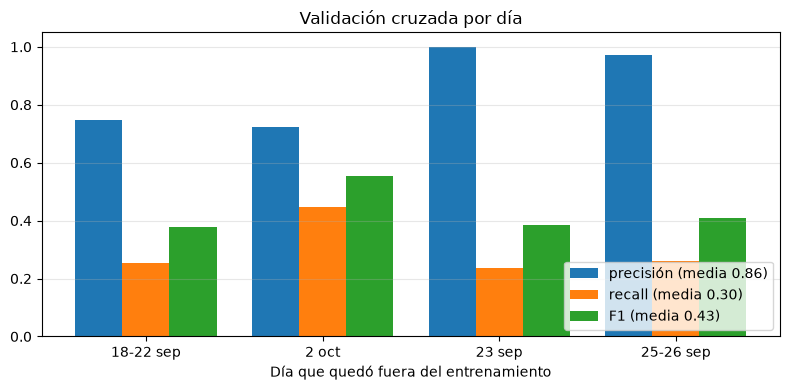

In [9]:
cv = sa.cross_validate(df)
result = sa.summary(cv)
sa.plot_cross_validation(cv, sa.RESULTS_DIR / "validacion_cruzada.png");

In [10]:
g, r = result["global"], result["reglas_fijas"]
pd.DataFrame({"LOF": g, "reglas fijas (36.5–38.5 °C, 40–75 %)": r}).loc[
    ["precision", "recall", "f1", "roc_auc", "falsos_positivos_pct"]]

,LOF,"reglas fijas (36.5–38.5 °C, 40–75 %)"
precision,0.84,0.23
recall,0.28,0.90
f1,0.42,0.36
roc_auc,0.77,NaN
falsos_positivos_pct,1.28,73.94


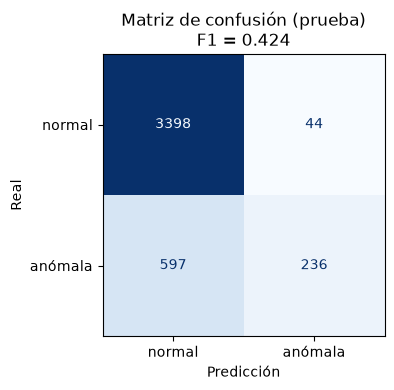

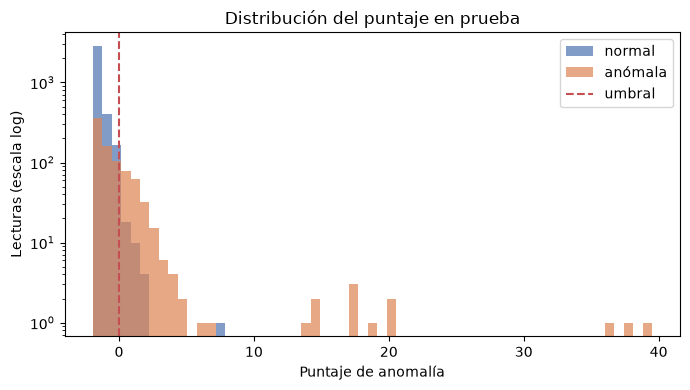

In [11]:
sa.plot_confusion({"matriz_confusion": g["matriz_confusion"], "f1": g["f1"]},
                  sa.RESULTS_DIR / "matriz_confusion.png")
sa.plot_distribution(cv["scores"][cv["use"]], 0.0, cv["label"][cv["use"]],
                     sa.RESULTS_DIR / "distribucion.png");

In [12]:
pd.DataFrame({
    "recall (lecturas)": result["recall_por_tipo"],
    "eventos detectados": {k: f"{v[0]}/{v[1]}" for k, v in result["eventos_detectados"].items()},
}).rename(index=sa.ANOMALY_TYPES)

,recall (lecturas),eventos detectados
Pico de temperatura (+6 °C en 2 lecturas),0.97,45/47
Calentamiento descontrolado (+0.5 °C por lectura),0.15,16/47
Foco encendido y la temperatura baja,0.11,3/18
Caída brusca de humedad (−25 %),0.98,7/7
Sensor desconectado (0 °C y 0 %),1.00,4/4


In [13]:
found, total = result["fallas_reales"]
print(f"Fallas reales del sensor detectadas: {found} de {total} lecturas")
print(f"Alertas falsas por hora (media por día): {result['por_dia']['alertas_falsas_por_hora'][0]:.1f}")

Fallas reales del sensor detectadas: 16 de 49 lecturas
Alertas falsas por hora (media por día): 6.6


### Comparación de algoritmos

In [14]:
comparison = sa.compare_models(df, chosen=result)
comparison.to_csv(sa.RESULTS_DIR / "comparacion_modelos.csv", float_format="%.4f")
comparison

,precision,recall,f1,roc_auc,falsos_positivos_pct,alertas_falsas_por_hora,eventos_pico,eventos_sobrecalentamiento,eventos_foco_sin_calentar,eventos_humedad,eventos_sensor
modelo,,,,,,,,,,,
Local Outlier Factor,0.84,0.28,0.42,0.77,1.28,6.62,45/47,16/47,3/18,7/7,4/4
Isolation Forest,0.92,0.07,0.13,0.81,0.15,0.00,8/47,1/47,0/18,6/7,4/4
One-Class SVM,0.77,0.55,0.64,0.82,4.07,28.92,47/47,46/47,9/18,7/7,4/4


### Análisis

- **LOF** detecta casi todos los **picos** de temperatura, las **caídas de humedad** y los **sensores desconectados**, con 1.3 % de falsos positivos por lectura y precisión 0.84.
- **Isolation Forest** separa bien en promedio (AUC parecido), pero con el umbral p99.9 casi no marca nada: sus puntajes de lecturas normales y anómalas se enciman en la cola. Con el umbral en p99 llega a recall 0.25 con 1.5 % de falsos positivos, un poco por debajo de LOF.
- **One-Class SVM** detecta más (también el calentamiento descontrolado), pero da ~4 veces más alertas falsas por hora. En una incubadora eso termina en alarmas que nadie atiende.
- **Las reglas fijas** de la Fase 2 marcan el 74 % de las lecturas normales: el histórico es casi todo calentamiento. El modelo no las reemplaza: el backend sigue vigilando los rangos y el modelo agrega lo que una regla no ve (cambios bruscos y lecturas inestables dentro del rango).

**Limitaciones:**

- El **calentamiento descontrolado** (+0.5 °C por lectura) y el **foco encendido con la temperatura bajando** se detectan poco: se parecen al calentamiento y al enfriamiento normales con la puerta abierta, que abundan en el histórico. Un sobrecalentamiento real termina pasando de 38.5 °C y lo atrapa la regla fija del backend.
- Las fallas son simuladas; no hay fallas reales etiquetadas aparte de las del sensor.
- El histórico es de 6 días con la incubadora casi siempre calentando. Con más días a 37.5 °C estables el modelo se volvería más sensible.
- Las alertas falsas varían mucho por día (0 a 17 por hora). La tasa más alta es la del día "2 oct" (17 por hora), el único con la puerta abierta más de la mitad del tiempo (54 %). Se pueden bajar con `ML_ALERT_NEEDED`/`ML_ALERT_WINDOW` sin reentrenar.

## 6. Modelo final y exportación

El modelo que se exporta se entrena con **todas** las lecturas normales. Se guarda con `joblib` junto con el umbral, el orden de las características y su media y desviación (para explicar la causa de cada anomalía).

In [15]:
final_model, final_threshold = sa.fit(features[normal])
path = sa.export_model(final_model, features[normal], final_threshold)
final = {"lecturas": int(normal.sum()), "umbral": final_threshold}
text = sa.report(result, final, comparison)
(sa.RESULTS_DIR / "reporte.txt").write_text(text)
print(text)
print(f"Modelo: {path}")

SmartEgg - detector de anomalías (Local Outlier Factor)

Validación cruzada dejando fuera un día (4 particiones): 4275 lecturas de prueba, 833 con fallas simuladas.
Umbral: percentil 99.9 del puntaje en operación normal. Alerta: 3 de las últimas 3 lecturas anómalas.

métrica (global)                           LOF  reglas fijas
precisión                                0.843         0.227
recall                                   0.283         0.899
F1                                       0.424         0.363
falsos positivos (%)                     1.278        73.940
ROC-AUC                                  0.772

Por día (media ± desv.):
  precisión                    0.861 ± 0.126
  recall                       0.299 ± 0.086
  F1                           0.431 ± 0.071
  falsos positivos (%)         1.133 ± 1.070
  alertas falsas por hora      6.619 ± 6.876

Recall por tipo de falla (lecturas) y eventos detectados:
  Pico de temperatura (+6 °C en 2 lecturas)             0.97   45/47 e

## 7. Integración al pipeline MQTT

El servicio `anomalias/anomaly_service.py` corre en Docker junto al broker:

1. Recibe cada lectura en vivo de `smartegg/{nodo}/telemetria`.
2. Calcula las características con el mismo `FeatureBuilder` y las califica con este modelo.
3. Publica `smartegg/{nodo}/ml/anomalia` (puntaje, umbral, `anomalia`, `alerta`, causa).
4. El backend guarda cada puntaje en `anomaly_scores` y abre la alarma `ml_anomaly` mientras haya alerta; Grafana grafica el puntaje contra el umbral.

```python
from anomaly_service import AnomalyModel, FeatureBuilder, Reading
model = AnomalyModel.load("modelo/smartegg_anomalias.joblib")
builder = FeatureBuilder()
features = builder.add(Reading(time=t, temperature=37.6, humidity=58.0))
if features is not None:
    score, anomalous, cause = model.score(features)
```